# 🔗 Projet 10 — Extraction de Relations entre Entités (Relation Extraction)

**Objectif :** à partir d'une phrase, trouver des triplets **(Entité 1, Relation, Entité 2)**.

> Exemple : « *Steve Jobs a fondé Apple* » → `(Steve Jobs, Fondateur_de, Apple)`

À la fin, tu auras un pipeline complet qui va d'un texte brut à un **graphe de connaissances**.

---

## 🗺️ Plan du notebook (= les 6 étapes du projet)

| # | Étape | Ce que tu produis |
|---|-------|-------------------|
| 1 | Dataset | Corpus annoté, plus de 5 000 triplets |
| 2 | Prétraitement | NER + dépendances syntaxiques + chemin entre entités |
| 3 | Représentation | Vecteurs (phrase + chemin syntaxique) |
| 4 | Modélisation | Classifieur de relations |
| 5 | Évaluation | F1-score + analyse des erreurs |
| 6 | Application | Knowledge Graph visualisé |

---

## 🧭 Comment utiliser ce notebook

Après **chaque cellule de code**, tu trouveras un bloc **🧠 À retenir et à réfléchir**.

Il contient :

- ce que la cellule vient de faire,
- la **relation** avec l'étape précédente et la suivante,
- des **questions** à te poser pour vraiment comprendre.

Lance les cellules **dans l'ordre**. Prends le temps de lire les sorties.

## 🧩 L'idée générale en 30 secondes

Une relation, c'est un lien **orienté** entre deux entités dans une phrase.

```
Phrase :  "Steve Jobs, the co-founder of Apple, ..."
              │                          │
           Entité 1                   Entité 2
              └──────  Fondateur_de ─────┘
```

Pour que la machine le trouve, on suit toujours le même fil :

1. **Trouver les entités** (NER) → qui sont les candidats ?
2. **Regarder la grammaire** (dépendances) → comment sont-ils reliés ?
3. **Transformer en nombres** (vectorisation) → pour un modèle.
4. **Classer** → quelle relation (ou aucune) ?
5. **Assembler** → les triplets forment un graphe.

Chaque étape alimente la suivante. Si l'une est mauvaise, tout le reste en souffre.

# ⚙️ Étape 0 — Installation et imports

In [1]:
# À lancer une seule fois (Colab ou local)
!pip -q install spacy scikit-learn networkx matplotlib pandas tqdm pyvis
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 25.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os, re, json, random, urllib.request, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import spacy
from spacy import displacy
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

print("spaCy version :", spacy.__version__)

spaCy version : 3.8.16


### 🧠 À retenir et à réfléchir

- **spaCy** fera le NER, la lemmatisation et l'analyse en dépendances.
- **scikit-learn** fera la vectorisation, le classifieur et le F1.
- **networkx** fera le chemin syntaxique **et** le graphe de connaissances final.

On fixe `SEED = 42` pour que tes résultats soient **reproductibles**.

**Question :** pourquoi est-ce important de fixer la graine quand on compare deux modèles ?

# 📥 Étape 1 — Dataset

## Le corpus : NYT10

Le sujet suggère le **NYT Corpus** (articles du New York Times, annotés par Riedel et al., 2010).

Chaque exemple contient :

- une **phrase**,
- une **entité tête** (head) et une **entité queue** (tail),
- une **relation** (par ex. `/people/person/place_lived`) ou `NA` si aucune relation connue.

## ⚠️ Annotation par « supervision distante »

Ce corpus n'a pas été annoté à la main.

On a pris une base de connaissances (Freebase) : si `(Obama, born_in, Honolulu)` existe, **toute phrase** qui contient Obama et Honolulu reçoit l'étiquette `born_in`.

C'est rapide, mais **bruité** : la phrase ne dit pas toujours la relation.

On garde ça en tête pour l'évaluation (étape 5).

In [3]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

NYT_URL  = "https://thunlp.oss-cn-qingdao.aliyuncs.com/opennre/benchmark/nyt10/nyt10_train.txt"
NYT_PATH = os.path.join(DATA_DIR, "nyt10_train.txt")
MIN_BYTES = 10_000_000   # en dessous, on considère le fichier comme invalide

def download(url, path):
    if os.path.exists(path) and os.path.getsize(path) > MIN_BYTES:
        print("Fichier déjà présent :", path)
        return True
    try:
        print("Téléchargement en cours (≈ 100 Mo, patience)...")
        urllib.request.urlretrieve(url, path)
        ok = os.path.getsize(path) > MIN_BYTES
    except Exception as e:
        print("Échec du téléchargement :", e)
        ok = False
    if not ok and os.path.exists(path):
        os.remove(path)
    return ok

NYT_OK = download(NYT_URL, NYT_PATH)
print("NYT10 disponible :", NYT_OK)

Téléchargement en cours (≈ 100 Mo, patience)...
NYT10 disponible : True


**Règle du projet : NYT10 uniquement.** Si le téléchargement échoue, placez le fichier officiel `nyt10_train.txt` dans `data/` puis relancez cette cellule. Le notebook s'arrête explicitement plutôt que de substituer un corpus synthétique.

Le modèle et toutes les métriques doivent être calculés sur le corpus NYT10 demandé.

**Contrôle :** la cellule suivante vérifie le format et l'échantillon obtenu avant de poursuivre.

In [4]:
if NYT_OK:
    with open(NYT_PATH, encoding="utf-8") as f:
        for _ in range(2):
            ex = json.loads(f.readline())
            print(json.dumps(ex, indent=1, ensure_ascii=False)[:700])
            print("-" * 60)
else:
    print("Pas de fichier NYT10 : on passera par le corpus de secours.")

{
 "text": "She also oversaw the refinancing of the state Superfund law ; the creation of a plan for decontaminating heavily polluted Onondaga Lake , near Syracuse ; the acquisition of hundreds of thousands of acres of Adirondack woodlands ; and the imposition of tough new acid rain rules .",
 "relation": "/location/location/contains",
 "h": {
  "id": "m.071cn",
  "name": "Syracuse",
  "pos": [
   143,
   151
  ]
 },
 "t": {
  "id": "m.02_v74",
  "name": "Onondaga Lake",
  "pos": [
   122,
   135
  ]
 }
}
------------------------------------------------------------
{
 "text": "More than 2.5 million cubic yards of contaminated mud will be dredged from Onondaga Lake , near Syracuse , under a consent decree between the state and Honeywell International that was announced yesterday .",
 "relation": "/location/location/contains",
 "h": {
  "id": "m.071cn",
  "name": "Syracuse",
  "pos": [
   96,
   104
  ]
 },
 "t": {
  "id": "m.02_v74",
  "name": "Onondaga Lake",
  "pos": [
   75,
   88
  

### 🧠 À retenir et à réfléchir

Regarde bien la structure d'un exemple :

- `text` : la phrase brute,
- `h` / `t` : nom, identifiant Freebase et **position** (`pos`) dans la phrase,
- `relation` : l'étiquette.

**Idée clé :** une relation n'existe jamais seule. Elle est toujours **attachée à une paire d'entités dans un contexte**.

Une même phrase peut donc donner plusieurs exemples (une par paire d'entités).

## 1.2 — Échantillonnage intelligent

Le fichier contient ≈ 500 000 lignes, dont **la grande majorité est `NA`**.

Si on prenait tout, le modèle apprendrait surtout à répondre « NA ».

On fait donc :

- les **10 relations les plus fréquentes**, max 700 exemples chacune,
- 2 500 exemples `NA` (pour apprendre à dire « pas de relation »),
- un tirage **aléatoire uniforme** (reservoir sampling) pour éviter un biais d'ordre dans le fichier.

In [5]:
K_PER_REL = 700    # exemples max par relation
N_NA      = 2500   # exemples "NA"
N_TOP_REL = 10     # nombre de relations gardées

def reservoir_load(path, k_rel=K_PER_REL, k_na=N_NA, seed=SEED):
    # Lit le fichier en flux et garde un échantillon uniforme par relation.
    rng = random.Random(seed)
    res, seen = defaultdict(list), Counter()
    with open(path, encoding="utf-8") as f:
        for line in tqdm(f, desc="Lecture NYT10"):
            ex = json.loads(line)
            rel = ex["relation"]
            cap = k_na if rel == "NA" else k_rel
            seen[rel] += 1
            if len(res[rel]) < cap:
                res[rel].append(ex)
            else:
                j = rng.randint(0, seen[rel] - 1)
                if j < cap:
                    res[rel][j] = ex
    return res, seen

def locate(text, ent):
    # Retrouve (début, fin) de l'entité ; vérifie que 'pos' est cohérent avec le texte.
    name = ent["name"]
    s, e = ent["pos"]
    if text[s:e] == name:
        return s, e
    i = text.find(name)
    return (i, i + len(name)) if i >= 0 else None

# Noms lisibles pour les relations les plus courantes de NYT10
REL_FR = {
    "/location/location/contains": "Contient",
    "/people/person/nationality": "Nationalite",
    "/location/country/capital": "Capitale",
    "/people/person/place_lived": "A_vecu_a",
    "/location/administrative_division/country": "Division_du_pays",
    "/location/country/administrative_divisions": "A_pour_division",
    "/business/person/company": "Travaille_pour",
    "/people/person/place_of_birth": "Ne_a",
    "/location/neighborhood/neighborhood_of": "Quartier_de",
    "/business/company/founders": "A_pour_fondateur",
    "/people/person/children": "A_pour_enfant",
    "/business/company/place_founded": "Fondee_a",
    "/people/deceased_person/place_of_death": "Mort_a",
}

def nyt_to_df(res, seen, n_top=N_TOP_REL):
    top = [r for r, _ in seen.most_common() if r != "NA"][:n_top]
    rows = []
    for rel in top + ["NA"]:
        for ex in res[rel]:
            text = ex["text"]
            if len(text) > 400:      # phrases trop longues = lent et bruité
                continue
            hp, tp = locate(text, ex["h"]), locate(text, ex["t"])
            if hp is None or tp is None:
                continue
            if not (hp[1] <= tp[0] or tp[1] <= hp[0]):   # chevauchement
                continue
            rows.append(dict(text=text, h=ex["h"]["name"], t=ex["t"]["name"],
                             h_start=hp[0], h_end=hp[1], t_start=tp[0], t_end=tp[1],
                             relation_raw=rel))
    df = pd.DataFrame(rows).drop_duplicates(["text", "h_start", "t_start"])
    df["relation"] = df["relation_raw"].map(lambda r: "NA" if r == "NA" else REL_FR.get(r, r.split("/")[-1]))
    return df.reset_index(drop=True)

### 🧠 À retenir et à réfléchir

**Reservoir sampling :** on lit le fichier **une seule fois** sans le charger en mémoire, et chaque ligne a la même chance d'être gardée. C'est une technique classique en Big Data (très utile pour ton master !).

**Le choix des classes est un choix scientifique :**

- trop peu de `NA` → le modèle verra des relations partout, même quand il n'y en a pas,
- trop de `NA` → il ne prédira presque jamais de relation.

**Remarque sur les noms :** `Contient` (Pays → Ville) et `Division_du_pays` (Ville → Pays) sont **inverses**.

La direction compte : `(France, Contient, Paris)` ≠ `(Paris, Contient, France)`.

**Question :** quelle autre façon de rééquilibrer les classes connais-tu (pondération, sur-échantillonnage...) ?

In [6]:
# NYT10 est le seul dataset autorisé pour ce projet : aucun corpus de remplacement.
if not NYT_OK:
    raise RuntimeError(
        "NYT10 indisponible. Téléchargez le fichier officiel OpenNRE "
        "nyt10_train.txt et placez-le dans le dossier data/, puis relancez. "
        "Aucun autre dataset ne sera utilisé."
    )

res, seen = reservoir_load(NYT_PATH)
df = nyt_to_df(res, seen)
SOURCE = "NYT10 (OpenNRE)"

# Identifiant de phrase : évite que la même phrase soit répartie entre train et test.
df["sid"] = df["text"].factorize()[0]

# Négatifs inversés : une relation positive dans le sens (h,t) ne doit pas
# être automatiquement prédite dans le sens inverse (t,h).
existing = set(zip(df["text"], df["h_start"], df["t_start"]))
rev = df[df["relation"] != "NA"].copy()
rev = rev[[
    (tx, ts, hs) not in existing
    for tx, hs, ts in zip(rev["text"], rev["h_start"], rev["t_start"])
]]
rev = rev.rename(columns={
    "h": "t", "t": "h", "h_start": "t_start", "h_end": "t_end",
    "t_start": "h_start", "t_end": "h_end"
})
rev["relation"] = "NA"
rev["relation_raw"] = "NA_inverse"
rev = rev.sample(frac=0.5, random_state=SEED)
df = pd.concat([df, rev[df.columns]], ignore_index=True)

assert SOURCE.startswith("NYT10"), "Le dataset doit être NYT10."
assert len(df) >= 5000, f"Échantillon insuffisant : {len(df)} exemples (minimum 5000)."
assert df[["text", "h", "t", "relation"]].notna().all().all(), "Valeurs manquantes dans les champs essentiels."
assert (df["h_start"] < df["h_end"]).all() and (df["t_start"] < df["t_end"]).all(), "Offsets d'entités invalides."
print(f"Dataset : {SOURCE}")
print(f"Lignes NYT10 lues : {sum(seen.values()):,}")
print(f"Triplets retenus après nettoyage et négatifs inversés : {len(df):,}")
print(f"Phrases distinctes : {df['sid'].nunique():,}")
print(f"Relations (incluant NA) : {df['relation'].nunique()}")
print("Contrôles dataset : OK")

Lecture NYT10: 0it [00:00, ?it/s]

Dataset : NYT10 (OpenNRE)
Lignes NYT10 lues : 522,611
Triplets retenus après nettoyage et négatifs inversés : 11,840
Phrases distinctes : 8,480
Relations (incluant NA) : 11
Contrôles dataset : OK


### 🧠 À retenir et à réfléchir

Le tableau final `df` est **ton corpus annoté**. Chaque ligne = un triplet :

`(h, relation, t)` + la phrase + les positions des entités.

**Vérifie le livrable :** le nombre de triplets doit être **≥ 5 000**.

S'il est trop bas, augmente `K_PER_REL` ou `N_TOP_REL`.

**Négatifs inversés :** si `(Steve Jobs, Fondateur_de, Apple)` est vrai, la paire **inversée** `(Apple, ?, Steve Jobs)` ne l'est pas. On l'ajoute comme exemple `NA`.

Sans ça, le modèle apprend « ces deux mots → Fondateur_de » et le prédit **dans les deux sens**. Avec ça, il apprend la **direction**.

**Bruit du corpus de secours :** si tu es passé par lui, ~5 % des étiquettes sont volontairement fausses, pour imiter la supervision distante. Ça rend l'analyse d'erreurs (étape 5) plus réaliste.

**Question :** pourquoi garde-t-on aussi `sid` (identifiant de phrase) ?

*Indice : une même phrase peut apparaître plusieurs fois avec des paires différentes. Si une moitié est dans le train et l'autre dans le test, le modèle « triche ».*

relation
NA                  5421
A_vecu_a             673
Nationalite          673
Contient             667
Division_du_pays     664
Travaille_pour       660
Capitale             646
Quartier_de          640
A_pour_division      619
Ne_a                 603
Mort_a               574


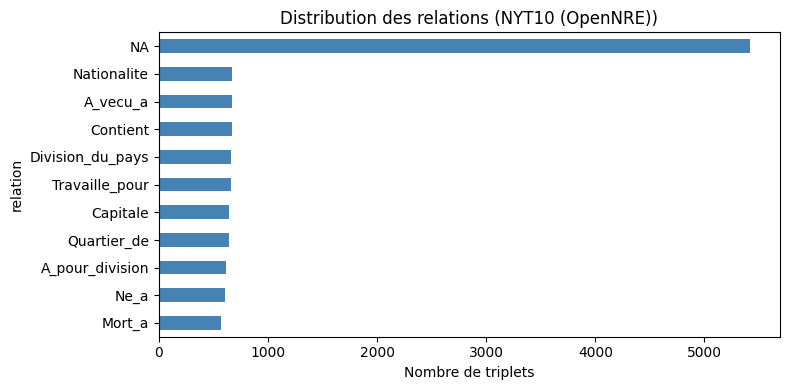

,h,relation,t,text
0,Pennsylvania,Contient,Philadelphia,He documents a continuing westward flow across the northern tier of the state and into Pennsylvania while ...
1,Ariel Sharon,Nationalite,Israel,"We are not partner to any agreement between various terror groups and the Palestinian Authority , '' said ..."
2,Faubourg Marigny,Quartier_de,New Orleans,"Mr. Anderson 's house in the Faubourg Marigny neighborhood survived , and his girlfriend , who graduated f..."
3,Allen Iverson,A_vecu_a,Philadelphia,Some subtle Celtics fans serenaded Philadelphia 's Allen Iverson on Wednesday night with chants of '' U.S....
4,Iraq,Capitale,Baghdad,A3 Suicide Bomber Kills 10 in Iraq A man wearing an explosive belt boarded a public minibus near Iraq 's p...
5,Neil deGrasse Tyson,Travaille_pour,Hayden Planetarium,"Tonight at 6:30 , '' A Scientist Goes to the Movies , '' with excerpts from the film '' Contact '' (1997) ..."
6,Lazio,Division_du_pays,Italy,"Eriksson , whose contract with the English Football Association runs through the European Championships in..."
7,Indonesia,A_pour_division,Yogyakarta,"Correction : June 8 , 2006 , Thursday Because of an editing error , an article on Monday about the increas..."
8,Paul Hester,Ne_a,Melbourne,"Paul Hester , the drummer for the New Zealand pop band Crowded House , was found dead on Saturday near his..."
9,Dorothy Kingsley,Mort_a,Hollywood,"A number of other old Hollywood pros , including the screenwriters Helen Deutsch and Dorothy Kingsley and ..."


In [7]:
# Distribution des relations
counts = df["relation"].value_counts()
print(counts.to_string())

plt.figure(figsize=(8, 4))
counts.sort_values().plot.barh(color="steelblue")
plt.title(f"Distribution des relations ({SOURCE})")
plt.xlabel("Nombre de triplets")
plt.tight_layout()
plt.show()

# Un exemple par relation
print()
display_cols = ["h", "relation", "t", "text"]
df.groupby("relation").head(1)[display_cols].reset_index(drop=True)

### 🧠 À retenir et à réfléchir

Regarde le graphique et les exemples **un par un**.

1. Quelle relation est la plus rare ? Le modèle aura plus de mal avec elle (peu d'exemples = peu de signal).
2. Dans chaque exemple, **la phrase exprime-t-elle vraiment la relation ?**
   Avec NYT10 tu verras des cas où non : c'est le bruit de la supervision distante.
3. Repère les **relations inverses** (ex : `Contient` / `Division_du_pays`).

**Idée pour ton rapport :** compte combien de phrases te semblent réellement correctes sur un petit échantillon de 20. C'est une estimation simple de la qualité des labels.

## 1.4 — Annoter toi-même des triplets

Le sujet demande d'**« identifier et annoter »** les triplets.

Voici comment on annote à la main : on indique la phrase, l'entité 1, la relation, l'entité 2. La fonction calcule les positions.

In [8]:
def annotate(text, head, relation, tail):
    # Crée une ligne d'annotation à partir de 3 informations simples.
    hs, ts = text.find(head), text.find(tail)
    assert hs >= 0 and ts >= 0, "Entité introuvable dans la phrase"
    return dict(text=text, h=head, t=tail, h_start=hs, h_end=hs+len(head),
                t_start=ts, t_end=ts+len(tail), relation_raw=relation, relation=relation)

manual = pd.DataFrame([
    annotate("Larry Page and Sergey Brin founded Google in California.", "Larry Page", "Fondateur_de", "Google"),
    annotate("Satya Nadella works for Microsoft in Redmond.", "Satya Nadella", "Travaille_pour", "Microsoft"),
    annotate("Rabat is the capital of Morocco.", "Rabat", "Capitale_de", "Morocco"),
])
manual["sid"] = -1 - np.arange(len(manual))     # ids négatifs : ne se mélangent pas au corpus
manual

,text,h,t,h_start,h_end,t_start,t_end,relation_raw,relation,sid
0,Larry Page and Sergey Brin founded Google in California.,Larry Page,Google,0,10,35,41,Fondateur_de,Fondateur_de,-1
1,Satya Nadella works for Microsoft in Redmond.,Satya Nadella,Microsoft,0,13,24,33,Travaille_pour,Travaille_pour,-2
2,Rabat is the capital of Morocco.,Rabat,Morocco,0,5,24,31,Capitale_de,Capitale_de,-3


### 🧠 À retenir et à réfléchir

L'annotation manuelle est la **vérité terrain** (gold standard) : plus fiable, mais **lente et chère**.

Bonnes pratiques à citer dans ton rapport :

- écrire des **règles d'annotation** (que faire si la relation est implicite ?),
- faire annoter par **deux personnes** et mesurer l'accord (kappa de Cohen),
- fixer la **direction** de chaque relation avant de commencer.

**Question :** supervision distante (rapide, bruitée) ou annotation manuelle (lente, propre) ?
Dans quel cas choisirais-tu l'une ou l'autre ?

On pourra utiliser ces 3 exemples manuels plus tard comme **mini-jeu de test à la main**.

In [9]:
# Sauvegarde du corpus annoté (livrable : corpus de phrases annotées)
df.to_csv("corpus_triplets.csv", index=False)
df.to_json("corpus_triplets.jsonl", orient="records", lines=True, force_ascii=False)
print("Fichiers créés : corpus_triplets.csv, corpus_triplets.jsonl")
print("Taille :", len(df), "triplets")

Fichiers créés : corpus_triplets.csv, corpus_triplets.jsonl
Taille : 11840 triplets


### 🧠 À retenir et à réfléchir

✅ **Livrable 1 terminé :** corpus de phrases annotées (≥ 5 000 triplets) avec un ensemble de relations prédéfinies.

On passe de la **donnée brute** à la **donnée structurée**. C'est la fondation de tout le reste.

# 🔍 Étape 2 — Prétraitement : NER + dépendances

On veut deux choses pour chaque paire d'entités :

1. leur **type** (PERSON, ORG, GPE...) → via le **NER**,
2. le **chemin syntaxique** qui les relie → via l'**analyse en dépendances**.

## Pourquoi c'est utile ?

- Le **type** élimine déjà des relations impossibles. `Fondateur_de` relie une PERSON à une ORG, jamais deux villes.
- Le **chemin** garde l'essentiel de la phrase et jette le bruit.

In [10]:
nlp = spacy.load("en_core_web_sm")

doc = nlp("Steve Jobs, the co-founder of Apple, was born in San Francisco.")

print("ENTITÉS (NER) :")
for e in doc.ents:
    print(f"  {e.text:15s} -> {e.label_}")

print("\nDÉPENDANCES (mot -> relation -> gouverneur) :")
for tok in doc:
    print(f"  {tok.text:12s} {tok.dep_:10s} -> {tok.head.text}")

ENTITÉS (NER) :
  Steve Jobs      -> PERSON
  Apple           -> ORG
  San Francisco   -> GPE

DÉPENDANCES (mot -> relation -> gouverneur) :
  Steve        compound   -> Jobs
  Jobs         nsubjpass  -> born
  ,            punct      -> Jobs
  the          det        -> co
  co           appos      -> Jobs
  -            appos      -> Jobs
  founder      appos      -> Jobs
  of           prep       -> founder
  Apple        pobj       -> of
  ,            punct      -> Jobs
  was          auxpass    -> born
  born         ROOT       -> born
  in           prep       -> born
  San          compound   -> Francisco
  Francisco    pobj       -> in
  .            punct      -> born


### 🧠 À retenir et à réfléchir

**NER :** `Steve Jobs → PERSON`, `Apple → ORG`, `San Francisco → GPE`. Ce sont nos **candidats**.

**Dépendances :** chaque mot dépend d'un autre. La phrase devient un **arbre**.

Exemples de labels utiles :

- `nsubj` : sujet du verbe,
- `dobj` : complément d'objet,
- `prep` / `pobj` : préposition et son complément,
- `appos` : apposition (« Steve Jobs, *the co-founder* »).

**Relation avec la suite :** la relation entre Jobs et Apple passe par l'**apposition** et la préposition `of`. C'est exactement ce qu'on veut capturer.

**Question :** si le verbe était « *was fired by* » au lieu de « *founded* », comment le chemin changerait-il ?

In [11]:
# Visualisation (dans Jupyter / Colab)
displacy.render(doc, style="ent", jupyter=True)
displacy.render(doc, style="dep", jupyter=True, options={"distance": 85, "compact": True})

### 🧠 À retenir et à réfléchir

Observe les flèches : elles vont du **gouverneur** vers le **dépendant**.

Pour aller de `Jobs` à `Apple`, on **remonte** puis on **redescend** dans l'arbre.

Ce trajet s'appelle le **chemin de dépendance le plus court** (*Shortest Dependency Path*, SDP).

📚 **L'hypothèse du SDP** (Bunescu & Mooney, 2005) : presque toute l'information utile sur la relation se trouve sur ce chemin.

C'est la grande idée de cette étape.

## 2.2 — Construire le chemin syntaxique

Le plan :

1. on transforme l'arbre en **graphe non orienté** (networkx),
2. on trouve le plus court chemin entre les deux entités,
3. on note chaque pas : `UP_xxx` (on remonte vers le gouverneur) ou `DOWN_xxx` (on descend vers un dépendant).

In [12]:
def build_graph(doc):
    # Arbre de dépendances -> graphe non orienté (nœuds = indices de tokens)
    g = nx.Graph()
    for tok in doc:
        g.add_node(tok.i)
        if tok.head.i != tok.i:
            g.add_edge(tok.i, tok.head.i)
    return g

def get_type(doc, span):
    # Type NER d'un span (ou "NONE" si spaCy ne le reconnaît pas comme entité)
    for ent in doc.ents:
        if ent.start < span.end and span.start < ent.end:
            return ent.label_
    return "NONE"

def dep_path(doc, g, h, t):
    # Chemin de dépendance le plus court de h vers t.
    a, b = h.root.i, t.root.i
    if a == b:
        return None
    try:
        nodes = nx.shortest_path(g, a, b)
    except nx.NetworkXNoPath:
        return None
    steps = []
    for u, v in zip(nodes[:-1], nodes[1:]):
        if doc[u].head.i == v:
            steps.append(f"UP_{doc[u].dep_}")      # on remonte vers le gouverneur
        else:
            steps.append(f"DOWN_{doc[v].dep_}")    # on descend vers un dépendant
    inner = [doc[i].lemma_.lower() for i in nodes[1:-1]]   # mots sur le chemin
    return steps, inner

def pair_features(doc, g, h, t):
    # Toutes les caractéristiques d'une paire (h, t) -> dictionnaire.
    p = dep_path(doc, g, h, t)
    if p is None:
        steps, inner = ["NOPATH"], []
    else:
        steps, inner = p
    h_first = h.start < t.start
    first, second = (h, t) if h_first else (t, h)
    between = doc[first.end:second.start]
    between_txt = " ".join(tok.lemma_.lower() for tok in between if not tok.is_space and not tok.is_punct)
    h_type, t_type = get_type(doc, h), get_type(doc, t)
    path_tokens = steps + ["W_" + w for w in inner] + ["PATH_" + "_".join(steps)]
    return dict(
        between=between_txt,            # mots entre les deux entités
        path=" ".join(path_tokens),     # chemin syntaxique + mots du chemin
        h_type=h_type, t_type=t_type, type_pair=f"{h_type}>{t_type}",
        order="HT" if h_first else "TH",   # h avant t dans la phrase ?
        dist=len(between),                 # distance en tokens
        path_len=len(steps),               # longueur du chemin
    )

def find_ent(doc, text):
    return next(e for e in doc.ents if e.text == text)

# --- Démonstration
g = build_graph(doc)
h, t = find_ent(doc, "Steve Jobs"), find_ent(doc, "Apple")
pair_features(doc, g, h, t)

{'between': 'the co founder of',
 'path': 'DOWN_appos DOWN_prep DOWN_pobj W_founder W_of PATH_DOWN_appos_DOWN_prep_DOWN_pobj',
 'h_type': 'PERSON',
 't_type': 'ORG',
 'type_pair': 'PERSON>ORG',
 'order': 'HT',
 'dist': 6,
 'path_len': 3}

### 🧠 À retenir et à réfléchir

Lis chaque champ :

- `between` : ce qui est écrit **entre** les entités. Simple, souvent suffisant pour des phrases courtes.
- `path` : la **structure grammaticale**. Résiste mieux quand les entités sont éloignées.
- `h_type`, `t_type`, `type_pair` : le **contrat de types** (PERSON>ORG).
- `order` : si on inverse `h` et `t`, la relation change de direction.
- `dist`, `path_len` : des mesures de « difficulté ». Plus c'est long, plus c'est implicite.

**Relation avec l'étape suivante :** ces champs sont encore du texte. L'étape 3 les transforme en nombres.

**Question :** teste avec `h = Apple` et `t = Steve Jobs`. Qu'est-ce qui change dans le chemin ? Pourquoi c'est important pour la direction ?

In [13]:
# Essai sur une autre paire de la même phrase
h2, t2 = find_ent(doc, "Apple"), find_ent(doc, "San Francisco")
print("Apple -> San Francisco :")
print(pair_features(doc, g, h2, t2))
print("\nSteve Jobs -> San Francisco :")
print(pair_features(doc, g, find_ent(doc, "Steve Jobs"), t2))

Apple -> San Francisco :
{'between': 'be bear in', 'path': 'UP_pobj UP_prep UP_appos UP_nsubjpass DOWN_prep DOWN_pobj W_of W_founder W_jobs W_bear W_in PATH_UP_pobj_UP_prep_UP_appos_UP_nsubjpass_DOWN_prep_DOWN_pobj', 'h_type': 'ORG', 't_type': 'GPE', 'type_pair': 'ORG>GPE', 'order': 'HT', 'dist': 4, 'path_len': 6}

Steve Jobs -> San Francisco :
{'between': 'the co founder of apple be bear in', 'path': 'UP_nsubjpass DOWN_prep DOWN_pobj W_bear W_in PATH_UP_nsubjpass_DOWN_prep_DOWN_pobj', 'h_type': 'PERSON', 't_type': 'GPE', 'type_pair': 'PERSON>GPE', 'order': 'HT', 'dist': 11, 'path_len': 3}


### 🧠 À retenir et à réfléchir

Même phrase, trois paires, trois chemins différents.

- `Jobs → San Francisco` passe par le verbe **born** et la préposition **in** : c'est une relation de naissance.
- `Apple → San Francisco` n'a **aucune** relation dans la phrase, mais le chemin est long et traverse plusieurs mots.

C'est exactement ce qui permettra au classifieur de distinguer une vraie relation d'un simple voisinage (`NA`).

## 2.3 — Appliquer à tout le corpus

On passe chaque phrase dans spaCy (`nlp.pipe` est beaucoup plus rapide qu'une boucle).

Ensuite, pour chaque ligne du corpus, on récupère les deux entités (avec leurs positions) et on calcule les caractéristiques.

⏱️ Compte 2 à 5 minutes selon ta machine.

In [14]:
def featurize(data, nlp, batch_size=64):
    feats, kept = [], []
    docs = nlp.pipe(data["text"].tolist(), batch_size=batch_size)
    for row, doc in tqdm(zip(data.itertuples(), docs), total=len(data), desc="Analyse syntaxique"):
        h = doc.char_span(row.h_start, row.h_end, alignment_mode="expand")
        t = doc.char_span(row.t_start, row.t_end, alignment_mode="expand")
        if h is None or t is None:
            continue
        if not (h.end <= t.start or t.end <= h.start):    # chevauchement après alignement
            continue
        g = build_graph(doc)
        feats.append(pair_features(doc, g, h, t))
        kept.append(row.Index)
    out = pd.DataFrame(feats, index=kept)
    meta = data.loc[kept, ["sid", "text", "h", "t", "relation"]]
    return pd.concat([meta, out], axis=1)

feat = featurize(df, nlp)
print(f"Triplets conservés : {len(feat)} / {len(df)}")
feat.to_pickle("features.pkl")
feat.head(5)

Analyse syntaxique:   0%|          | 0/11840 [00:00<?, ?it/s]

Triplets conservés : 11840 / 11840


,sid,text,h,t,relation,between,path,h_type,t_type,type_pair,order,dist,path_len
0,0,He documents a continuing westward flow across the northern tier of the state and into Pennsylvania while ...,Pennsylvania,Philadelphia,Contient,while,UP_pobj UP_conj UP_prep UP_dobj DOWN_advcl DOWN_nsubj W_into W_across W_flow W_document W_send PATH_UP_pob...,GPE,GPE,GPE>GPE,HT,1,6
1,1,IF YOU GO Asturias is nestled between Cantabria and Galicia in the north of Spain .,Spain,Galicia,Contient,in the north of,UP_pobj UP_prep UP_pobj UP_prep DOWN_prep DOWN_pobj DOWN_conj W_of W_north W_in W_nestle W_between W_canta...,GPE,PERSON,GPE>PERSON,TH,4,7
2,2,"Lubbock or Leave It , '' a fierce country-rocker , describes Ms. Maines 's Texas hometown as a hypocritica...",Texas,Lubbock,Contient,or leave it a fierce country rocker describe ms. maines 's,UP_compound UP_dobj DOWN_nsubj W_hometown W_describe PATH_UP_compound_UP_dobj_DOWN_nsubj,GPE,NONE,GPE>NONE,TH,15,3
3,3,"Correction : July 22 , 2006 , Saturday An article on Tuesday about the sentencing of Nicholas Minucci to 1...",Queens,Lindenwood,Contient,last year refer incorrectly to,UP_appos UP_appos UP_npadvmod DOWN_prep DOWN_pobj W_article W_correction W_refer W_to PATH_UP_appos_UP_app...,GPE,ORG,GPE>ORG,HT,6,5
4,4,"That event was held in his hometown , Park City , Utah , and Ligety was 17 and a member of the local ski t...",Utah,Park City,Contient,,UP_conj PATH_UP_conj,GPE,GPE,GPE>GPE,TH,1,1


### 🧠 À retenir et à réfléchir

✅ **Livrable 2 :** le script d'analyse syntaxique et de détection d'entités (`build_graph`, `get_type`, `dep_path`, `pair_features`, `featurize`).

Regarde `feat.head()` : chaque ligne est maintenant **un candidat de relation** décrit par des caractéristiques linguistiques.

Si des triplets ont été perdus : ce sont des cas où spaCy ne découpe pas les tokens comme l'annotation. C'est normal, c'est une limite à mentionner.

**Analyse rapide à faire dans ton rapport :**
quel pourcentage d'entités du corpus spaCy reconnaît-il avec un type (autre que `NONE`) ? C'est la cellule suivante.

In [15]:
print("Types des entités tête (h) :")
print(feat["h_type"].value_counts().head(8).to_string())
print("\nPaires de types les plus fréquentes par relation :")
tab = (feat[feat["relation"] != "NA"]
       .groupby("relation")["type_pair"]
       .agg(lambda s: s.value_counts().head(2).to_dict()))
print(tab.to_string())

none_rate = ((feat["h_type"] == "NONE") | (feat["t_type"] == "NONE")).mean()
print(f"\nPaires avec au moins une entité non reconnue par le NER : {none_rate:.1%}")

Types des entités tête (h) :
h_type
GPE            6138
PERSON         3906
ORG             999
NONE            244
LOC             240
NORP            144
FAC             108
WORK_OF_ART      26

Paires de types les plus fréquentes par relation :
relation
A_pour_division            {'GPE>GPE': 532, 'GPE>ORG': 23}
A_vecu_a             {'PERSON>GPE': 582, 'PERSON>ORG': 28}
Capitale                  {'GPE>GPE': 573, 'NORP>GPE': 17}
Contient                   {'GPE>GPE': 399, 'LOC>GPE': 65}
Division_du_pays           {'GPE>GPE': 574, 'ORG>GPE': 21}
Mort_a               {'PERSON>GPE': 479, 'PERSON>ORG': 20}
Nationalite             {'PERSON>GPE': 544, 'ORG>GPE': 25}
Ne_a                    {'PERSON>GPE': 478, 'ORG>GPE': 30}
Quartier_de                {'GPE>GPE': 353, 'LOC>GPE': 62}
Travaille_pour      {'PERSON>ORG': 470, 'PERSON>GPE': 134}

Paires avec au moins une entité non reconnue par le NER : 3.8%


### 🧠 À retenir et à réfléchir

Regarde le tableau « paires de types par relation ».

- `Travaille_pour` → `PERSON>ORG` : cohérent.
- `Contient` → `GPE>GPE` : cohérent.

Les **types sont déjà très discriminants**. C'est une des raisons pour lesquelles ils seront dans le vecteur.

Le taux de `NONE` mesure la **propagation d'erreurs** : si le NER rate une entité, le classifieur n'a pas son type.

**Idée :** dans une chaîne (pipeline), l'erreur d'une étape est héritée par la suivante. Les approches *end-to-end* (un seul modèle) essaient d'éviter ça.

# 🔢 Étape 3 — Représentation (vectorisation)

Un classifieur ne comprend que des nombres. On transforme nos champs texte en vecteurs.

| Champ | Technique | Idée |
|-------|-----------|------|
| `between` | TF-IDF (1-2 grammes) | Les mots entre les entités |
| `path` | TF-IDF (1-2 grammes) | La structure syntaxique |
| types, ordre | One-hot | Catégories |
| `dist`, `path_len` | Mise à l'échelle | Nombres |

On assemble tout avec `ColumnTransformer`. Les blocs sont **concaténés** en un grand vecteur creux.

## Séparation train / test

On sépare **par phrase** (`sid`), avec les classes bien réparties (`StratifiedGroupKFold`).

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, MaxAbsScaler
from sklearn.model_selection import StratifiedGroupKFold

def make_prep(blocks):
    # Construit le transformeur avec uniquement les blocs demandés (utile pour l'ablation).
    catalog = {
        "between": lambda: ("between", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "between"),
        "path":    lambda: ("path", TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2,
                                                    sublinear_tf=True, lowercase=False), "path"),
        "types":   lambda: ("types", OneHotEncoder(handle_unknown="ignore"), ["h_type", "t_type", "type_pair", "order"]),
        "num":     lambda: ("num", MaxAbsScaler(), ["dist", "path_len"]),
    }
    return ColumnTransformer([catalog[b]() for b in blocks])

ALL_BLOCKS = ["between", "path", "types", "num"]

# Split 80 / 20 par phrase, stratifié par relation
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(feat, feat["relation"], groups=feat["sid"]))
train, test = feat.iloc[train_idx], feat.iloc[test_idx]

assert set(train["sid"]).isdisjoint(set(test["sid"])), "Fuite : une phrase est dans train ET test"
print(f"Train : {len(train)}   Test : {len(test)}")
print("\nRépartition (%) des relations :")
print(pd.concat([train["relation"].value_counts(normalize=True).rename("train"),
                 test["relation"].value_counts(normalize=True).rename("test")], axis=1).mul(100).round(1).to_string())

# Vectorisation
prep = make_prep(ALL_BLOCKS)
X_train = prep.fit_transform(train)     # fit UNIQUEMENT sur le train
X_test = prep.transform(test)
print("\nForme de la matrice train :", X_train.shape)
print(f"Densité : {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.3%} de valeurs non nulles")

Train : 9457   Test : 2383

Répartition (%) des relations :
                  train  test
relation                     
NA                 45.5  46.9
A_vecu_a            5.7   5.5
Nationalite         5.7   5.6
Division_du_pays    5.7   5.3
Contient            5.6   5.6
Travaille_pour      5.6   5.5
Capitale            5.5   5.4
Quartier_de         5.5   5.2
A_pour_division     5.3   5.1
Ne_a                5.1   5.1
Mort_a              4.9   4.8

Forme de la matrice train : (9457, 30520)
Densité : 0.110% de valeurs non nulles


### 🧠 À retenir et à réfléchir

**Trois idées à retenir :**

1. **`fit` sur le train seulement.** Si le vocabulaire TF-IDF voit le test, c'est une fuite d'information.
2. **Split par phrase.** L'`assert` vérifie qu'aucune phrase n'est des deux côtés.
3. **Matrice creuse :** quelques dizaines de milliers de colonnes, presque toutes à zéro. C'est normal en NLP et ça reste rapide.

**Pourquoi deux TF-IDF (`between` et `path`) ?**

- `between` capte le *lexique* (« born in », « founder of »),
- `path` capte la *grammaire* (`UP_appos DOWN_prep`), même si les mots changent.

**Question :** lequel des deux, selon toi, va le plus aider quand les entités sont très éloignées ? Tu vas le **vérifier** juste après.

In [17]:
# Regardons un peu à l'intérieur : les caractéristiques les plus "lourdes"
names = prep.get_feature_names_out()
print("Exemples de colonnes :")
for i in np.random.RandomState(0).choice(len(names), 12, replace=False):
    print("  ", names[i])

Exemples de colonnes :
   between__of michael
   between__public school
   between__gunmen assassinate
   path__W_holt
   between__of townsville
   between__out talk
   between__require
   between__code and
   between__rob
   between__exile group
   between__drug
   between__other provincial


### 🧠 À retenir et à réfléchir

Chaque colonne a un **préfixe** : `between__`, `path__`, `types__`, `num__`.

Tu vois bien que le vecteur est **interprétable** : on pourra dire *quelle caractéristique pousse vers quelle relation*. C'est un avantage énorme sur un modèle neuronal « boîte noire ».

✅ **Livrable 3 :** vecteurs de représentation incluant des caractéristiques syntaxiques.

# 🤖 Étape 4 — Modélisation

## 4.1 — Baseline puis vrai modèle

On compare toujours à une **baseline** : sans elle, un score ne veut rien dire.

- **Dummy** : prédit toujours la classe la plus fréquente.
- **Régression logistique** : un classique, rapide, interprétable, et qui donne des **probabilités** (utile pour le graphe final).
- **Métrique principale :** F1 **micro sur les vraies relations** (on exclut `NA`), comme dans la littérature, et F1 macro pour voir toutes les classes.

In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

y_train, y_test = train["relation"].values, test["relation"].values
POS = sorted(set(y_train) - {"NA"})          # vraies relations

def scores(y_true, y_pred):
    return dict(
        F1_micro_sans_NA=f1_score(y_true, y_pred, labels=POS, average="micro"),
        F1_macro_sans_NA=f1_score(y_true, y_pred, labels=POS, average="macro"),
        accuracy=accuracy_score(y_true, y_pred),
    )

# Baseline
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline (classe majoritaire) :", {k: round(v, 3) for k, v in scores(y_test, dummy.predict(X_test)).items()})

# Régression logistique
clf = LogisticRegression(max_iter=3000, C=4, class_weight="balanced")
clf.fit(X_train, y_train)
pred = clf.predict(X_test)
print("Régression logistique        :", {k: round(v, 3) for k, v in scores(y_test, pred).items()})

Baseline (classe majoritaire) : {'F1_micro_sans_NA': 0.0, 'F1_macro_sans_NA': 0.0, 'accuracy': 0.469}
Régression logistique        : {'F1_micro_sans_NA': 0.427, 'F1_macro_sans_NA': 0.426, 'accuracy': 0.548}


### 🧠 À retenir et à réfléchir

**Regarde l'écart baseline vs modèle.** C'est la vraie mesure de ce que le modèle a appris.

**Pourquoi exclure `NA` du F1 ?** Si on l'incluait, prédire « NA » partout donnerait un bon score (classe majoritaire) sans rien extraire. On veut mesurer la capacité à **trouver les vraies relations**.

**Pourquoi `class_weight="balanced"` ?** Les erreurs sur les classes rares comptent plus. Sinon le modèle favorise les classes fréquentes.

**Question :** que se passe-t-il si tu enlèves `class_weight="balanced"` ? Essaie et compare.

## 4.2 — Ablation : quelles caractéristiques servent vraiment ?

On réentraîne le même modèle en **retirant des blocs** de caractéristiques.

C'est LA cellule qui prouve l'intérêt de l'analyse syntaxique, et c'est un résultat à mettre en avant dans ton rapport.

                               F1_micro_sans_NA  F1_macro_sans_NA  accuracy
configuration                                                              
between seul (sac de mots)                0.245             0.236     0.274
path seul (syntaxe)                       0.322             0.327     0.396
types seuls (NER)                         0.271             0.216     0.403
between + types                           0.372             0.367     0.496
path + types                              0.408             0.408     0.517
TOUT (between+path+types+num)             0.427             0.426     0.548


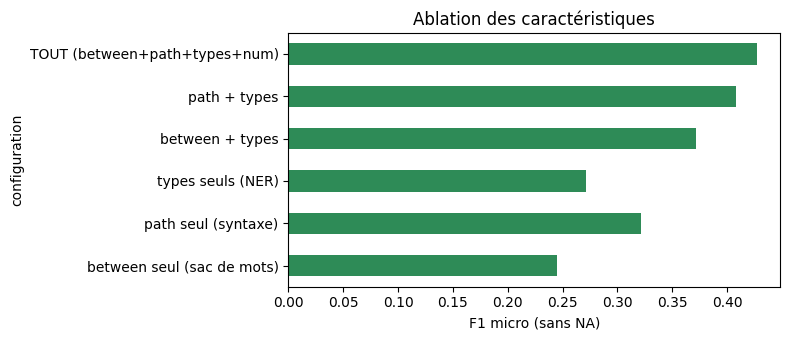

In [19]:
configs = {
    "between seul (sac de mots)":  ["between"],
    "path seul (syntaxe)":         ["path"],
    "types seuls (NER)":           ["types"],
    "between + types":             ["between", "types"],
    "path + types":                ["path", "types"],
    "TOUT (between+path+types+num)": ALL_BLOCKS,
}

rows = []
for name, blocks in configs.items():
    p = make_prep(blocks)
    m = Pipeline([("prep", p), ("clf", LogisticRegression(max_iter=3000, C=4, class_weight="balanced"))])
    m.fit(train, y_train)
    s = scores(y_test, m.predict(test))
    rows.append(dict(configuration=name, **{k: round(v, 3) for k, v in s.items()}))

ablation = pd.DataFrame(rows).set_index("configuration")
display(ablation) if "display" in globals() else print(ablation)

ablation["F1_micro_sans_NA"].plot.barh(color="seagreen", figsize=(8, 3.5))
plt.xlabel("F1 micro (sans NA)")
plt.title("Ablation des caractéristiques")
plt.tight_layout()
plt.show()

### 🧠 À retenir et à réfléchir

Lis le tableau comme une enquête :

1. **`between` seul vs `path` seul :** lequel gagne ? Sur des phrases courtes ils se ressemblent. Sur NYT10 (phrases longues), la syntaxe aide davantage.
2. **Les types seuls** donnent déjà un score non négligeable : la paire de types **restreint** les relations possibles.
3. **TOUT ensemble** doit être le meilleur ou très proche : les informations sont **complémentaires**.

**Pour le rapport :** écris une phrase du type « *l'ajout du chemin syntaxique améliore le F1 de X points par rapport au sac de mots* ». C'est ton argument principal.

**Question :** si `path` n'apporte presque rien sur ton corpus, quelles peuvent être les raisons ? (corpus synthétique trop simple ? phrases très courtes ? labels bruités ?)

## 4.3 — Réglage du modèle

On cherche la meilleure force de régularisation `C` par validation croisée (3 plis, **par groupes de phrases**).

In [20]:
from sklearn.model_selection import GridSearchCV, GroupKFold

pipe = Pipeline([("prep", make_prep(ALL_BLOCKS)),
                 ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])

grid = GridSearchCV(pipe, {"clf__C": [0.5, 2, 8, 32]}, scoring="f1_macro",
                    cv=GroupKFold(n_splits=3), n_jobs=-1)
grid.fit(train, y_train, groups=train["sid"])

print("Meilleur C :", grid.best_params_["clf__C"])
res_cv = pd.DataFrame(grid.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]]
print(res_cv.round(3).to_string(index=False))

final = grid.best_estimator_            # pipeline complet (prep + clf), déjà réentraîné
pred = final.predict(test)
print("\nModèle final :", {k: round(v, 3) for k, v in scores(y_test, pred).items()})

Meilleur C : 2
 param_clf__C  mean_test_score  std_test_score
          0.5            0.427           0.004
          2.0            0.433           0.004
          8.0            0.431           0.003
         32.0            0.426           0.002

Modèle final : {'F1_micro_sans_NA': 0.425, 'F1_macro_sans_NA': 0.424, 'accuracy': 0.537}


### 🧠 À retenir et à réfléchir

- **`C` petit** = modèle très régularisé (simple, risque de sous-apprendre).
- **`C` grand** = modèle libre (risque de sur-apprentissage).

La validation croisée se fait **dans le train**. Le test reste **intouchable** jusqu'à la mesure finale.

`final` est un **pipeline complet** : il prend directement un DataFrame de caractéristiques et prédit. On le réutilisera pour le graphe.

**Pistes d'amélioration (à mentionner dans le rapport) :**

- `LinearSVC` ou `XGBoost` à la place de la régression logistique,
- un modèle de langage (BERT) avec marqueurs d'entités (`[E1] ... [/E1]`),
- ajouter les embeddings des mots du chemin.

✅ **Livrable 4 :** modèle de classification de relations.

# 📊 Étape 5 — Évaluation et analyse des erreurs

## 5.1 — Scores détaillés par relation

Un score global cache les différences. On regarde **précision, rappel, F1 pour chaque relation**.

In [21]:
print(classification_report(y_test, pred, digits=3, zero_division=0))

                  precision    recall  f1-score   support

 A_pour_division      0.238     0.331     0.277       121
        A_vecu_a      0.438     0.371     0.402       132
        Capitale      0.301     0.438     0.357       128
        Contient      0.245     0.376     0.297       133
Division_du_pays      0.280     0.417     0.335       127
          Mort_a      0.384     0.461     0.419       115
              NA      0.891     0.593     0.712      1117
     Nationalite      0.465     0.594     0.521       133
            Ne_a      0.269     0.289     0.279       121
     Quartier_de      0.495     0.750     0.596       124
  Travaille_pour      0.703     0.826     0.760       132

        accuracy                          0.537      2383
       macro avg      0.428     0.495     0.450      2383
    weighted avg      0.622     0.537     0.560      2383



### 🧠 À retenir et à réfléchir

**Rappel des définitions :**

- **Précision** : quand je prédis cette relation, ai-je raison ? (peu de faux positifs)
- **Rappel** : parmi les vraies instances, combien j'en trouve ? (peu de faux négatifs)
- **F1** : moyenne harmonique des deux.

**Ce qu'il faut regarder :**

1. Les relations avec un F1 **bas** : pourquoi ? Peu d'exemples ? Ambiguïté ? Proches d'une autre relation ?
2. La précision de `NA` : un rappel de `NA` bas signifie qu'on **invente** des relations.
3. Le `support` : une classe à 20 exemples est peu fiable statistiquement.

**Question :** dans une application « base de connaissances », qu'est-ce qui coûte le plus cher : un faux positif ou un faux négatif ?

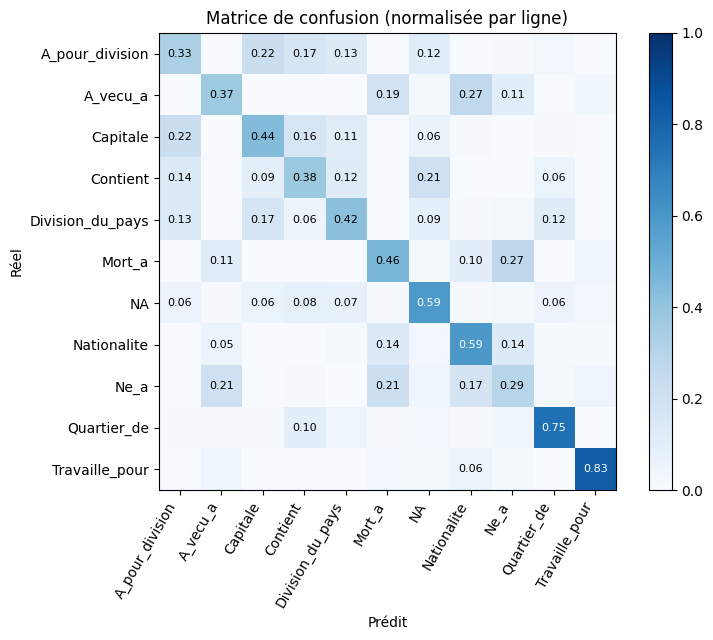

In [22]:
labels = sorted(set(y_test) | set(pred))
cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
ax.set_title("Matrice de confusion (normalisée par ligne)")
plt.colorbar(im, fraction=0.046)
plt.tight_layout()
plt.show()

### 🧠 À retenir et à réfléchir

Chaque **ligne** = la vraie classe, chaque **colonne** = la prédiction. La diagonale = les bonnes réponses.

Cherche les **cases hors diagonale** colorées :

- Confusion entre deux relations proches (ex : `Ne_a` ↔ `A_vecu_a`) : sémantiquement voisines, c'est compréhensible.
- Confusion avec `NA` : le modèle hésite entre « relation » et « pas de relation ».

Chaque grosse confusion est une **hypothèse** à tester avec les exemples réels (cellule suivante).

## 5.2 — Ce que le modèle a appris (interprétabilité)

Avec une régression logistique, on peut lire les **poids** : quelles caractéristiques poussent vers chaque relation ?

In [23]:
prep_f = final.named_steps["prep"]
clf_f = final.named_steps["clf"]
fnames = prep_f.get_feature_names_out()

for i, cls in enumerate(clf_f.classes_):
    if cls == "NA":
        continue
    top = np.argsort(clf_f.coef_[i])[::-1][:8]
    print(f"{cls:18s} <- " + " | ".join(fnames[j].split("__", 1)[1] for j in top))

A_pour_division    <- UP_poss | W_state | W_begin | h_type_GPE | survey | write | UP_poss UP_dobj | W_give
A_vecu_a           <- DOWN_compound | W_governor | gov | h_type_PERSON | DOWN_pobj W_with | W_republican | republican | rapper
Capitale           <- UP_poss | W_capital | that | administrative | path_len | UP_poss UP_appos | antwerp | american
Contient           <- UP_appos | W_have | type_pair_LOC>GPE | PATH_UP_appos | UP_appos PATH_UP_appos | UP_compound | DOWN_pobj DOWN_conj | trip
Division_du_pays   <- DOWN_poss | DOWN_poss W_in | fiorentina | W_in W_bear | DOWN_nsubj | capital | UP_compound | DOWN_nsubj W_in
Mort_a             <- W_die | W_live | DOWN_pobj W_die | h_type_PERSON | in | W_die W_in | president of | during
Nationalite        <- lrb | not | president | DOWN_poss | W_of PATH_DOWN_prep_DOWN_pobj | DOWN_pobj DOWN_appos | PATH_UP_dobj_DOWN_prep_DOWN_pobj | h_type_PERSON
Ne_a               <- h_type_PERSON | W_bear | DOWN_compound | W_catch | tight end | tight | govern

### 🧠 À retenir et à réfléchir

Tu viens de lire **les indices que le modèle utilise** pour chaque relation.

Tu devrais voir :

- des mots-clés (`found`, `born`, `capital`...),
- des motifs de chemin (`UP_appos`, `DOWN_prep`...),
- des paires de types (`PERSON>ORG`).

**Test de bon sens :** ces indices ont-ils un sens linguistique ? Si le modèle s'appuie sur un détail absurde (un nom propre précis, un mot sans rapport), c'est un signe de **sur-apprentissage** ou de **biais du corpus**.

C'est un argument de qualité pour ton rapport.

## 5.3 — Erreurs selon la difficulté (distance et longueur du chemin)

Le sujet demande d'examiner les cas où la relation est **implicite** ou nécessite un **raisonnement au-delà de la phrase**.

Premier indicateur simple : plus les entités sont éloignées, moins la relation est explicite.

Accuracy selon la distance (en tokens) entre les entités :
            n  accuracy
bin_dist               
0-2       611     0.537
3-6       505     0.626
7-12      527     0.520
13-25     552     0.467
26+       188     0.548

Accuracy selon la longueur du chemin syntaxique :
            n  accuracy
path_len               
1         320     0.481
2         304     0.661
3         340     0.688
4         203     0.542
5         240     0.546
6         219     0.516
7         212     0.476
8         545     0.431


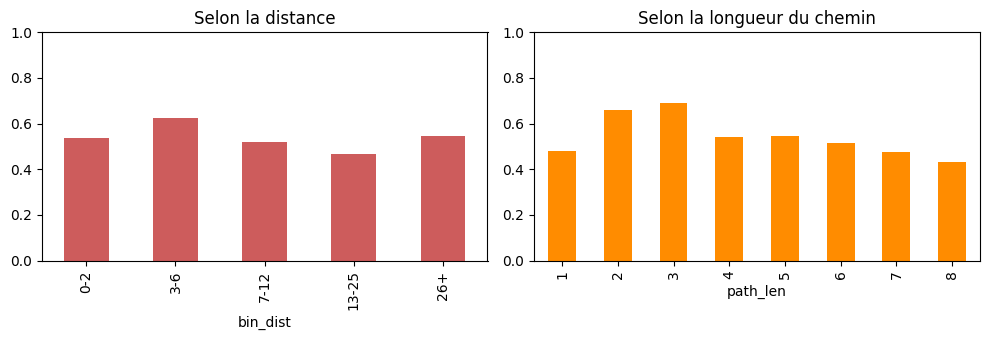

In [24]:
ev = test.copy()
ev["pred"] = pred
ev["ok"] = (ev["pred"] == ev["relation"]).astype(int)
ev["proba"] = final.predict_proba(test).max(axis=1)

ev["bin_dist"] = pd.cut(ev["dist"], [-1, 2, 6, 12, 25, 1000], labels=["0-2", "3-6", "7-12", "13-25", "26+"])
by_dist = ev.groupby("bin_dist", observed=True).agg(n=("ok", "size"), accuracy=("ok", "mean"))
print("Accuracy selon la distance (en tokens) entre les entités :")
print(by_dist.round(3).to_string())

by_path = ev.groupby(ev["path_len"].clip(upper=8)).agg(n=("ok", "size"), accuracy=("ok", "mean"))
print("\nAccuracy selon la longueur du chemin syntaxique :")
print(by_path.round(3).to_string())

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
by_dist["accuracy"].plot.bar(ax=axs[0], color="indianred"); axs[0].set_title("Selon la distance"); axs[0].set_ylim(0, 1)
by_path["accuracy"].plot.bar(ax=axs[1], color="darkorange"); axs[1].set_title("Selon la longueur du chemin"); axs[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

### 🧠 À retenir et à réfléchir

Si l'accuracy **baisse** quand la distance augmente, tu as une preuve chiffrée : *les relations lointaines/implicites sont plus difficiles*.

Attention à `n` : un groupe avec peu d'exemples donne un pourcentage instable.

**Remarque pour le rapport :** sur un corpus synthétique très régulier, la courbe sera presque plate (phrases toutes simples). Sur NYT10, elle est plus parlante.

**Question :** pourquoi le chemin syntaxique devrait-il mieux résister à la distance que le simple « texte entre les entités » ?

## 5.4 — Lire les erreurs une par une

Les chiffres disent **combien** on se trompe. Les exemples disent **pourquoi**.

On classe chaque erreur dans une famille, puis on lit des cas concrets.

In [25]:
def error_family(r):
    if r["relation"] == "NA":
        return "Faux positif : relation inventée (ou label NA discutable)"
    if r["pred"] == "NA":
        return "Relation manquée (implicite / formulation rare)"
    return "Confusion entre deux relations"

errors = ev[ev["ok"] == 0].copy()
if errors.empty:
    errors["famille"] = []
else:
    errors["famille"] = errors.apply(error_family, axis=1)
print(f"{len(errors)} erreurs sur {len(ev)} ({len(errors)/len(ev):.1%})\n")
print(errors["famille"].value_counts().to_string())

# Lecture de cas concrets
for fam, sub in errors.groupby("famille"):
    print("\n" + "=" * 90)
    print(fam.upper())
    for _, r in sub.sample(min(4, len(sub)), random_state=SEED).iterrows():
        print(f"\n  Phrase : {r['text'][:230]}")
        print(f"  Paire  : ({r['h']}) --?--> ({r['t']})")
        print(f"  Réel = {r['relation']:16s} Prédit = {r['pred']:16s} confiance = {r['proba']:.2f}")
        print(f"  Distance = {r['dist']} tokens | chemin : {r['path'].split(' W_')[0]}")

1104 erreurs sur 2383 (46.3%)

famille
Confusion entre deux relations                               568
Faux positif : relation inventée (ou label NA discutable)    455
Relation manquée (implicite / formulation rare)               81

CONFUSION ENTRE DEUX RELATIONS

  Phrase : The couple also had a Muslim ceremony performed in London in August by Dr. Syed Mohiud-Din , a medical doctor in Surrey , England , who is sanctioned to perform Muslim ceremonies by the Muslim Cultural and Welfare Association ther
  Paire  : (England) --?--> (London)
  Réel = Capitale         Prédit = Contient         confiance = 0.33
  Distance = 15 tokens | chemin : UP_appos UP_pobj UP_prep UP_appos UP_pobj UP_agent DOWN_prep DOWN_pobj

  Phrase : Forster also passed along Cavafy 's poems to T. S. Eliot and others in England .
  Paire  : (T. S. Eliot) --?--> (England)
  Réel = Nationalite      Prédit = Mort_a           confiance = 0.49
  Distance = 3 tokens | chemin : UP_pobj UP_prep DOWN_prep DOWN_pobj

  Phra

### 🧠 À retenir et à réfléchir

**Prends 10 minutes et lis vraiment les erreurs.** Pour chacune, demande-toi :

1. **Le label était-il correct ?** (supervision distante : souvent non !)
2. **La phrase exprime-t-elle la relation ?** Parfois les deux entités sont juste dans la même phrase.
3. **Le NER a-t-il raté une entité ?** (types `NONE`)
4. **La relation est-elle implicite ?** Il faut une connaissance du monde (« Paris, France » → Paris est *dans* la France sans verbe).

## Les 4 causes classiques d'erreurs (à structurer dans ton rapport)

| Cause | Exemple | Piste |
|-------|---------|-------|
| **Bruit des labels** | Obama et Hawaï dans une phrase sans lien de naissance | Filtrage, apprentissage multi-instance |
| **Relation implicite** | « *Paris, France* » (juste une virgule) | Connaissances externes, modèles pré-entraînés |
| **Raisonnement multi-phrases** | « *Il a fondé la société* » (qui est « Il » ?) | Résolution de coréférence |
| **Erreur du NER / parseur** | Entité non reconnue ou arbre faux | Meilleurs modèles (`en_core_web_trf`) |

La cellule suivante illustre la **3e cause**.

# 🕸️ Étape 6 — Application : Knowledge Graph

## 6.1 — Du texte brut aux triplets

On enchaîne tout le pipeline sur un **texte nouveau** :

1. spaCy découpe en phrases et détecte les entités,
2. pour **chaque paire ordonnée** d'entités dans une phrase, on calcule les caractéristiques,
3. le modèle prédit la relation et une **probabilité**,
4. on garde les prédictions ≠ `NA` avec une confiance suffisante.

In [26]:
ENT_TYPES = {"PERSON", "ORG", "GPE", "LOC", "NORP", "FAC"}

def extract_triples(text, threshold=0.5):
    # Texte brut -> liste de triplets (h, relation, t, proba, phrase).
    doc = nlp(text)
    g = build_graph(doc)
    cand, rows = [], []
    for sent in doc.sents:
        ents = [e for e in sent.ents if e.label_ in ENT_TYPES]
        for h in ents:
            for t in ents:
                if h.start == t.start:
                    continue
                cand.append((h, t, sent.text.strip()))
                rows.append(pair_features(doc, g, h, t))
    if not rows:
        return []
    probs = final.predict_proba(pd.DataFrame(rows))
    classes = final.classes_
    out = []
    for (h, t, s), p in zip(cand, probs):
        k = p.argmax()
        if classes[k] != "NA" and p[k] >= threshold:
            out.append(dict(h=h.text, relation=classes[k], t=t.text, proba=round(float(p[k]), 3), phrase=s))
    return out

corpus = (
    "Steve Jobs founded Apple in Cupertino. "
    "Tim Cook works for Apple, which is headquartered in Cupertino. "
    "Jeff Bezos founded Amazon in Seattle. "
    "Satya Nadella works for Microsoft in Redmond. "
    "Barack Obama was born in Honolulu. "
    "Paris is the capital of France. "
    "Rabat is the capital of Morocco. "
    "Casablanca is a large city in Morocco. "
    "Larry Page founded Google. "
    "Brooklyn is a borough of New York City."
)

triples = pd.DataFrame(extract_triples(corpus, threshold=0.4))
triples = triples.sort_values("proba", ascending=False).drop_duplicates(["h", "relation", "t"])
triples[["h", "relation", "t", "proba"]].reset_index(drop=True)

,h,relation,t,proba
0,Tim Cook,Travaille_pour,Apple,0.929
1,Satya Nadella,Travaille_pour,Microsoft,0.929
2,Jeff Bezos,Travaille_pour,Amazon,0.888
3,Larry Page,Travaille_pour,Google,0.888
4,Steve Jobs,Travaille_pour,Apple,0.888
5,Paris,Division_du_pays,France,0.737
6,Redmond,Contient,Microsoft,0.575
7,Cupertino,Contient,Apple,0.502
8,Seattle,Contient,Amazon,0.502
9,Jeff Bezos,A_vecu_a,Seattle,0.494


### 🧠 À retenir et à réfléchir

C'est **le moment de vérité** : le modèle voit des phrases qu'il n'a jamais rencontrées.

Pour chaque triplet, juge à la main :

- ✅ correct,
- ❌ faux (relation inventée ou mauvaise direction),
- ❓ manquant (une relation évidente n'apparaît pas).

**Le seuil `threshold` règle le compromis précision/rappel :**

- seuil haut (0.8) → peu de triplets, mais fiables,
- seuil bas (0.3) → plus de triplets, mais plus d'erreurs.

Change-le et regarde ce qui arrive.

**Important :** les relations disponibles dépendent du **corpus d'entraînement** (NYT10 → lieux, nationalité, entreprise...). Le modèle ne peut pas deviner une relation qu'il n'a jamais vue.

In [27]:
# Limite : le raisonnement au-delà de la phrase
test_text = "Steve Jobs was a businessman. He founded Apple in California."
print("Triplets trouvés :")
for r in extract_triples(test_text, threshold=0.3):
    print(" ", (r["h"], r["relation"], r["t"], r["proba"]))

d = nlp(test_text)
print("\nEntités vues par spaCy :", [(e.text, e.label_) for e in d.ents])
print("Le mot 'He' est-il une entité ? ->", any(e.text == "He" for e in d.ents))

Triplets trouvés :
  ('Apple', 'Mort_a', 'California', 0.396)
  ('California', 'Contient', 'Apple', 0.502)

Entités vues par spaCy : [('Steve Jobs', 'PERSON'), ('Apple', 'ORG'), ('California', 'GPE')]
Le mot 'He' est-il une entité ? -> False


### 🧠 À retenir et à réfléchir

Le pronom **« He »** n'est pas une entité nommée : notre pipeline ne peut pas relier `Elon Musk` à `SpaceX` à travers deux phrases.

Il faudrait ajouter une **résolution de coréférence** (« He » = Elon Musk), puis remplacer le pronom avant l'extraction.

C'est **exactement** le cas « raisonnement au-delà de la phrase » demandé dans l'étape 5 du sujet. Garde cet exemple dans ton rapport.

**Autre limite :** notre classifieur regarde **une phrase à la fois**. Pour des relations entre phrases, on parle d'**extraction de relations au niveau document** (corpus DocRED).

## 6.2 — Construire et visualiser le graphe

Chaque triplet devient une **arête orientée** dans un graphe : les entités sont les **nœuds**, les relations sont les **étiquettes** des arêtes.

Graphe : 18 nœuds, 15 relations


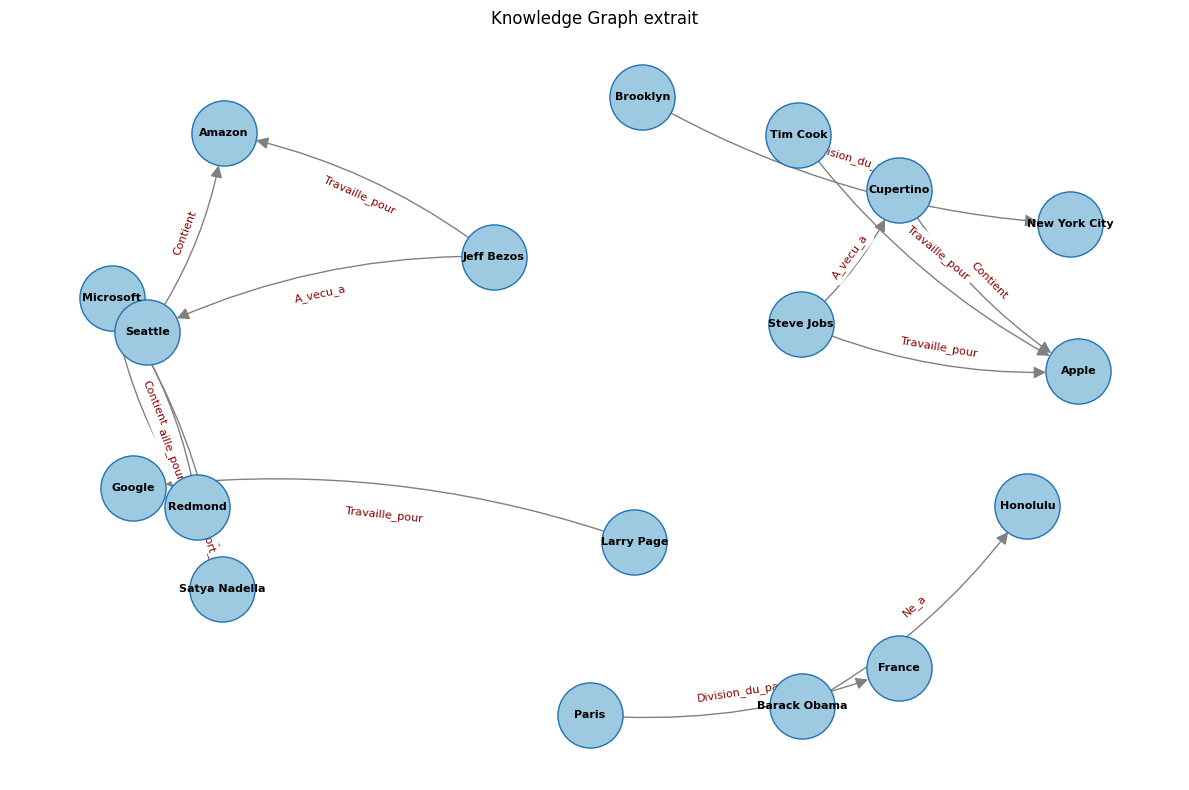

In [28]:
def build_kg(triples_df):
    G = nx.MultiDiGraph()
    for r in triples_df.itertuples():
        G.add_edge(r.h, r.t, relation=r.relation, proba=r.proba)
    return G

KG = build_kg(triples)
print(f"Graphe : {KG.number_of_nodes()} nœuds, {KG.number_of_edges()} relations")

def draw_kg(G, title="Knowledge Graph extrait"):
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, seed=SEED, k=1.1)
    nx.draw_networkx_nodes(G, pos, node_size=2200, node_color="#9ecae1", edgecolors="#2171b5")
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold")
    nx.draw_networkx_edges(G, pos, edge_color="gray", arrows=True, arrowsize=18, node_size=2200,
                           connectionstyle="arc3,rad=0.12")
    labels = {(u, v): d["relation"] for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=labels, font_size=8, font_color="darkred", label_pos=0.5)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("knowledge_graph.png", dpi=150)
    plt.show()

draw_kg(KG)

### 🧠 À retenir et à réfléchir

Le graphe est enregistré dans `knowledge_graph.png` (**livrable 6**).

**Pourquoi un graphe plutôt qu'une table ?**

Parce qu'on peut **raisonner** dessus : suivre des chemins, trouver des voisins, combiner des faits.

Exemple : si `(Tim Cook, Travaille_pour, Apple)` et `(Apple, Siege_a, Cupertino)`, on déduit que Tim Cook travaille à Cupertino, **sans que ce soit écrit dans une phrase**.

C'est le lien entre extraction de relations et **raisonnement**.

**Question :** repère les nœuds avec le plus de connexions. Que représentent-ils ?

In [29]:
# Interroger le graphe
def about(G, entity):
    print(f"--- {entity} ---")
    for u, v, d in G.out_edges(entity, data=True):
        print(f"  {u} --[{d['relation']}]--> {v}")
    for u, v, d in G.in_edges(entity, data=True):
        print(f"  {u} --[{d['relation']}]--> {v}")

for ent in list(KG.nodes)[:3]:
    about(KG, ent)

print("\nDegré des nœuds (nombre de connexions) :")
print(sorted(dict(KG.degree()).items(), key=lambda x: -x[1])[:5])

--- Tim Cook ---
  Tim Cook --[Travaille_pour]--> Apple
--- Apple ---
  Tim Cook --[Travaille_pour]--> Apple
  Steve Jobs --[Travaille_pour]--> Apple
  Cupertino --[Contient]--> Apple
--- Satya Nadella ---
  Satya Nadella --[Travaille_pour]--> Microsoft
  Satya Nadella --[Mort_a]--> Redmond

Degré des nœuds (nombre de connexions) :
[('Apple', 3), ('Microsoft', 3), ('Redmond', 3), ('Satya Nadella', 2), ('Jeff Bezos', 2)]


### 🧠 À retenir et à réfléchir

Tu as maintenant une **mini-base de connaissances interrogeable**.

Pour aller plus loin, tu peux ajouter :

- un seuil sur la probabilité pour filtrer les arêtes douteuses,
- la fusion d'entités qui ont plusieurs noms (« NYC », « New York City »),
- une base de graphe (Neo4j) pour de grands corpus.

In [30]:
# (Optionnel) Version interactive avec pyvis -> fichier HTML
try:
    from pyvis.network import Network
    net = Network(height="600px", width="100%", directed=True, cdn_resources="in_line")
    for n in KG.nodes:
        net.add_node(n, label=n)
    for u, v, d in KG.edges(data=True):
        net.add_edge(u, v, label=d["relation"], title=f"p={d['proba']}")
    net.save_graph("knowledge_graph.html")
    print("Graphe interactif sauvegardé : knowledge_graph.html (ouvre-le dans ton navigateur)")
except Exception as e:
    print("pyvis non disponible, ce n'est pas grave :", e)

Graphe interactif sauvegardé : knowledge_graph.html (ouvre-le dans ton navigateur)


# ✅ Conclusion et plan du rapport

## Checklist des livrables

| Étape | Livrable | Où dans le notebook |
|-------|----------|--------------------|
| 1 | Corpus annoté (≥ 5 000 triplets) | `df`, fichiers `corpus_triplets.csv/.jsonl` |
| 2 | Script d'analyse syntaxique et NER | `build_graph`, `pair_features`, `featurize` |
| 3 | Vecteurs avec caractéristiques syntaxiques | `make_prep`, `X_train` |
| 4 | Modèle de classification | `final` (pipeline) |
| 5 | Rapport d'évaluation + analyse des erreurs | sections 5.1 à 5.4 |
| 6 | Visualisation du Knowledge Graph | `knowledge_graph.png` / `.html` |

## Plan suggéré pour ton rapport

1. **Introduction** : problème, intérêt (bases de connaissances, QA, moteurs de recherche).
2. **Données** : NYT10, supervision distante, échantillonnage, distribution des relations.
3. **Méthode** : NER → SDP → TF-IDF + types → régression logistique.
4. **Résultats** : tableau d'ablation, F1 par relation, matrice de confusion.
5. **Analyse d'erreurs** : les 4 familles (bruit, implicite, multi-phrases, erreur NER/parseur).
6. **Application** : le graphe.
7. **Limites et perspectives.**

## 🚀 Pour aller plus loin

- **BERT / RoBERTa** avec marqueurs d'entités (état de l'art sur TACRED, NYT10).
- **Apprentissage multi-instance** (MIL) : traiter un *sac* de phrases par paire d'entités pour réduire le bruit.
- **Résolution de coréférence** (`coreferee`, `fastcoref`) avant l'extraction.
- **Extraction conjointe** NER + relations (REBEL, un modèle seq2seq qui génère directement les triplets).
- **Niveau document** : DocRED.

---

### 🎯 Les 5 idées à garder en tête

1. Une relation est un lien **orienté** entre deux entités **dans un contexte**.
2. Le **type** des entités et le **chemin syntaxique** sont des indices très forts.
3. Les labels par supervision distante sont **bruités** : toujours lire des exemples.
4. On évalue **sans `NA`**, et on compare à une **baseline**.
5. Les erreurs racontent plus de choses que les scores.

## 🖥️ Étape 7 — Interface de l'application (Streamlit)

Cette étape exporte le modèle final entraîné pour que l'interface web puisse l'utiliser. Exécute cette cellule **après toutes les cellules précédentes**, notamment après l'entraînement final (`final`).

Les fichiers `app.py` et `relation_extraction_core.py` fournis avec le projet doivent être placés dans le même dossier que ce notebook.

In [ ]:
from pathlib import Path
import joblib

ARTIFACT_DIR = Path('artifacts')
ARTIFACT_DIR.mkdir(exist_ok=True)
joblib.dump(final, ARTIFACT_DIR / 'relation_model.joblib')
print('Modèle exporté vers :', ARTIFACT_DIR / 'relation_model.joblib')
print('Classes apprises :', list(final.classes_))
print('\nEnsuite, dans le terminal : streamlit run app.py')